# **🔋 EV Battery Failure Risk Prediction (ML)**

**Goal:** Predict whether an EV battery has **Low / Medium / High failure risk** from its usage, charging and sensor data.

**What this notebook covers**
1. Load & understand the data
2. Check the target and missing values
3. Remove *leaky* columns (very important!)
4. Simple feature engineering
5. Train models: Baseline → Logistic Regression → Random Forest → Gradient Boosting
6. Compare models, check errors, see important features
7. Conclusion

## **1. Import Libraries**

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

sns.set_style("whitegrid"); RANDOM = 42

## **2. Load the Data**

In [2]:
import glob
paths = glob.glob("/kaggle/input/datasets/vinay24baghira/ev-battery-health-and-degradation-dataset/ev_battery_health.csv", recursive=True) + ["/mnt/user-data/uploads/ev_battery_health.csv", "ev_battery_health.csv"]
import os
df = pd.read_csv(next(p for p in paths if os.path.exists(p)))
print(df.shape)
df.head()

(50000, 35)


,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


## **3. Understand the Target**
`failure_risk_label` is what we want to predict. Notice the classes are **imbalanced** (most batteries are Low risk), so plain *accuracy* can be misleading. We will also use **Macro F1**, which treats every class equally.

failure_risk_label
Low       0.855
Medium    0.088
High      0.057
Name: proportion, dtype: float64


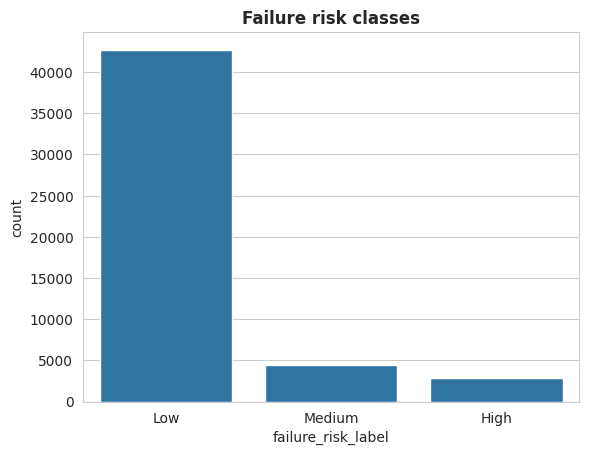

In [3]:
print(df["failure_risk_label"].value_counts(normalize=True).round(3))
sns.countplot(data=df, x="failure_risk_label", order=["Low","Medium","High"])
plt.title("Failure risk classes",fontweight='bold'); plt.show()

## **4. Missing Values**
Many columns have ~5% missing values. We will fill them later inside the model pipeline (so no information leaks from test data).

In [4]:
miss = (df.isna().mean()*100).sort_values(ascending=False)
miss[miss>0].head(10).round(1)

last_service_date              37.7
vehicle_model                   7.0
chemistry                       6.9
fast_charge_ratio               6.8
total_energy_throughput_kwh     6.7
avg_ambient_temp_c              6.6
avg_state_of_charge_pct         6.3
battery_age_days                6.0
avg_depth_of_discharge_pct      5.7
voltage_avg_v                   5.6
dtype: float64

## **5. Remove Leaky Columns ⚠️**
Some columns are **results of battery damage**, not causes. Using them would give a fake "perfect" score that is useless in real life:
- `state_of_health_pct` and `capacity_fade_pct` (they are exactly `100 - each other`, and *are* the damage)
- `remaining_useful_life_cycles` and `degradation_category` (outcomes of the same degradation)
- IDs (`battery_id`, `observation_id`) – no real meaning

We keep the usage, charging, environment and sensor features only.

In [5]:
leaky = ["state_of_health_pct","capacity_fade_pct","remaining_useful_life_cycles","degradation_category","battery_id","observation_id"]
groups = df["battery_id"]          # same battery appears many times -> used for a fair split
y = df["failure_risk_label"]
X = df.drop(columns=leaky+["failure_risk_label"])
X.shape

(50000, 28)

## **6. Feature Engineering**
We turn dates into useful numbers: how long since last service, whether the battery was ever serviced, and simple ratios.

In [6]:
for c in ["manufacture_date","observation_date","last_service_date"]:
    X[c] = pd.to_datetime(X[c], errors="coerce")

X["days_since_service"] = (X["observation_date"] - X["last_service_date"]).dt.days
X["never_serviced"]     = X["last_service_date"].isna().astype(int)
X["cycles_per_day"]     = X["cycle_count"] / X["battery_age_days"]
X["energy_per_cycle"]   = X["total_energy_throughput_kwh"] / X["cycle_count"]
X = X.drop(columns=["manufacture_date","observation_date","last_service_date"])
X = X.replace([np.inf,-np.inf], np.nan)

cat_cols = X.select_dtypes("object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print("Categorical:", cat_cols); print("Numeric:", len(num_cols))

Categorical: ['chemistry', 'manufacturer', 'vehicle_model', 'climate_zone', 'bms_firmware_version']
Numeric: 24


## **7. Train / Test Split**
The **same battery** appears in many rows. If it appears in both train and test, the model just "remembers" it. So we split **by battery** (`GroupShuffleSplit`) for an honest score.

In [7]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM)
tr, te = next(gss.split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
print(X_train.shape, X_test.shape)

(39866, 29) (10134, 29)


## **8. Preprocessing**
- **Linear model:** fill missing values (median / most frequent), scale numbers, one-hot encode text.
- **Tree models:** fill missing values and ordinal-encode text (no scaling needed).

In [8]:
linear_prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

tree_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oe", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), cat_cols)])

## **9. Train Models: Baseline → Best**
We use `class_weight='balanced'` so the rare Medium/High classes are not ignored.

In [9]:
models = {
 "Baseline (most frequent)": Pipeline([("p", linear_prep), ("m", DummyClassifier(strategy="most_frequent"))]),
 "Logistic Regression":      Pipeline([("p", linear_prep), ("m", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
 "Random Forest":            Pipeline([("p", tree_prep),   ("m", RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced", n_jobs=-1, random_state=RANDOM))]),
 "Gradient Boosting":        Pipeline([("p", tree_prep),   ("m", HistGradientBoostingClassifier(learning_rate=0.08, max_iter=300, class_weight="balanced", random_state=RANDOM))]),
}
rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict(X_test); preds[name] = p
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test,p), "Macro F1": f1_score(y_test,p,average="macro")})
results = pd.DataFrame(rows).sort_values("Macro F1", ascending=False).round(4).reset_index(drop=True)
results

,Model,Accuracy,Macro F1
0,Random Forest,0.9486,0.8524
1,Gradient Boosting,0.9340,0.8408
2,Logistic Regression,0.9083,0.8043
3,Baseline (most frequent),0.8591,0.3081


## **10. Compare Models**

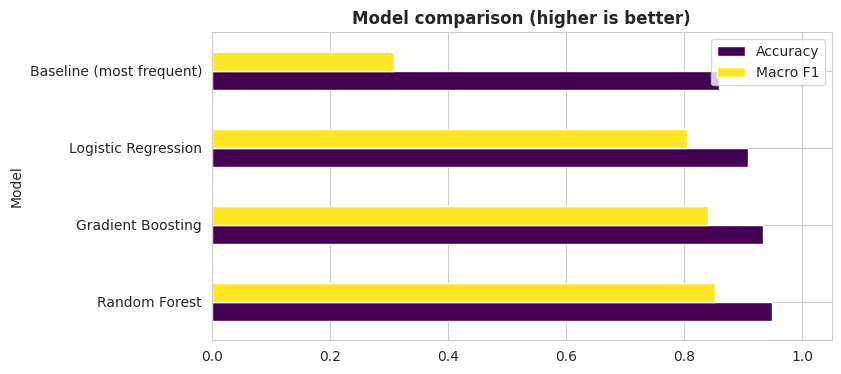

In [10]:
results.set_index("Model")[["Accuracy","Macro F1"]].plot(kind="barh", figsize=(8,4), colormap="viridis")
plt.title("Model comparison (higher is better)",fontweight='bold'); plt.xlim(0,1.05); plt.show()

## **11. Best Model: Detailed Report**
The confusion matrix shows where the model is right (diagonal) and where it confuses classes.

Best model: Random Forest 

              precision    recall  f1-score   support

        High      0.911     0.828     0.868       570
         Low      0.979     0.977     0.978      8706
      Medium      0.683     0.742     0.711       858

    accuracy                          0.949     10134
   macro avg      0.858     0.849     0.852     10134
weighted avg      0.950     0.949     0.949     10134



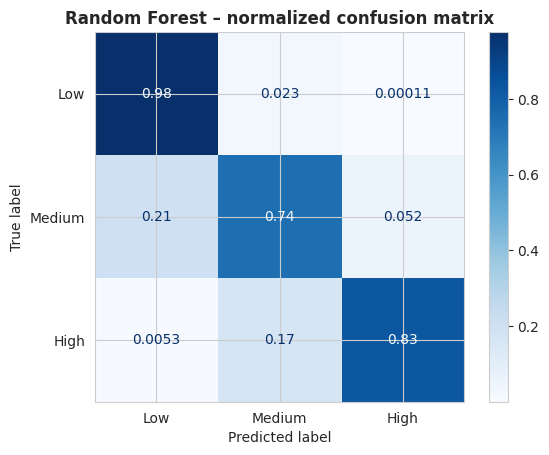

In [11]:
best = results.loc[0,"Model"]; print("Best model:", best, "\n")
print(classification_report(y_test, preds[best], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, preds[best], labels=["Low","Medium","High"], cmap="Blues", normalize="true")
plt.title(f"{best} – normalized confusion matrix",fontweight='bold'); plt.show()

## **12. Which Features Matter?**
Permutation importance: shuffle one feature and see how much the score drops.

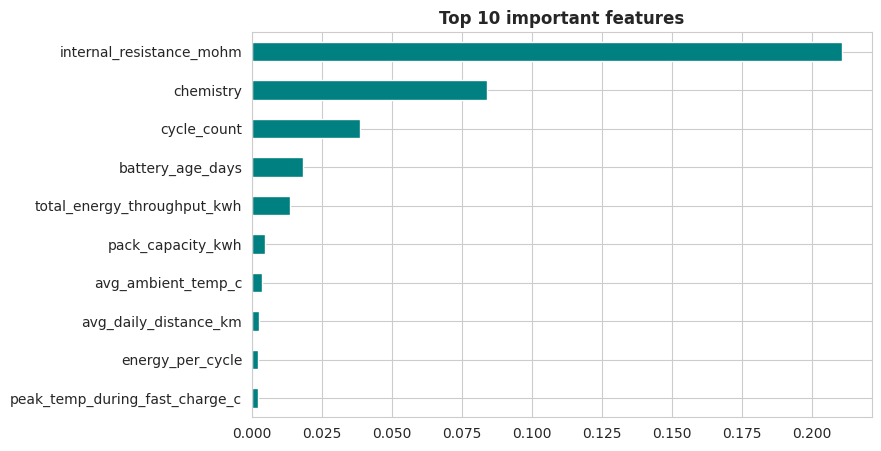

In [12]:
pi = permutation_importance(models[best], X_test, y_test, scoring="f1_macro", n_repeats=3, random_state=RANDOM, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10)
imp[::-1].plot(kind="barh", figsize=(8,5), color="teal"); plt.title("Top 10 important features",fontweight='bold'); plt.show()

## **13. Conclusion ✅**

| Model | Accuracy | Macro F1 |
|---|---|---|
| Baseline (most frequent) | 0.859 | 0.308 |
| Logistic Regression | 0.908 | 0.804 |
| Gradient Boosting | 0.934 | 0.841 |
| **Random Forest (best)** | **0.949** | **0.852** |

**Key points**
- The baseline gets 86% accuracy only by always saying "Low", yet its Macro F1 is just 0.31. This is why we judged models on **Macro F1** as well.
- Random Forest is the best model: **94.9% accuracy** on batteries it has never seen (split by battery, leaky columns removed), so the score is honest.
- **Internal resistance** is by far the strongest signal, followed by **battery chemistry**, **cycle count**, **age** and **energy throughput**.
- The weakest class is **Medium** risk (F1 ≈ 0.71), because it sits between Low and High and is hard to separate.

**Next steps:** tune hyperparameters (RandomizedSearchCV), try XGBoost/LightGBM, and tune class thresholds to catch more High-risk batteries.